# Robustness Check

`model_comparison.ipynb` used one random split with about 99 test frauds, so its numbers could be luck. This notebook repeats the whole experiment on **5 different random splits** and reports the average and spread. It also repeats one run **after removing duplicate rows**.

Same method each time: 60/20/20 stratified split, class-weighted models, threshold chosen on the validation set at the assumed false-alarm cost, results measured once on the test set.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, average_precision_score

DATA_FILE = "creditcard.csv" if os.path.exists("creditcard.csv") else "creditcard.csv.zip"
df = pd.read_csv(DATA_FILE)
features = [f"V{i}" for i in range(1, 29)] + ["Amount"]

FALSE_ALARM_COST = 5   # ASSUMPTION, same as the other notebooks
SEEDS = [42, 43, 44, 45, 46]
thresholds = np.linspace(0.01, 0.99, 99)
print("Rows:", len(df), "| frauds:", int(df["Class"].sum()))

Rows: 284807 | frauds: 492


In [2]:
def total_cost(y_true, proba, amount, thr, fa_cost):
    actual = y_true.values
    flagged = proba >= thr
    missed = (actual == 1) & (~flagged)
    false_alarms = (actual == 0) & flagged
    return amount[missed].sum() + fa_cost * false_alarms.sum()

def run_experiment(data, seed, label):
    X, y = data[features], data["Class"]
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=seed)
    X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=seed)

    scaler = StandardScaler().fit(X_tr[["Amount"]])
    def scale(p):
        p = p.copy(); p["Amount"] = scaler.transform(p[["Amount"]]); return p
    Xs_tr, Xs_val, Xs_te = scale(X_tr), scale(X_val), scale(X_te)

    amt_val = data.loc[X_val.index, "Amount"].values
    amt_te = data.loc[X_te.index, "Amount"].values
    cost_none = amt_te[y_te.values == 1].sum()

    models = {
        "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=seed),
        "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=5,
                                                class_weight="balanced_subsample", n_jobs=-1, random_state=seed),
    }
    rows = []
    for name, m in models.items():
        m.fit(Xs_tr, y_tr)
        p_val = m.predict_proba(Xs_val)[:, 1]
        p_te = m.predict_proba(Xs_te)[:, 1]
        pred = (p_te >= 0.5).astype(int)
        val_costs = [total_cost(y_val, p_val, amt_val, t, FALSE_ALARM_COST) for t in thresholds]
        best_thr = thresholds[int(np.argmin(val_costs))]
        cost_best = total_cost(y_te, p_te, amt_te, best_thr, FALSE_ALARM_COST)
        rows.append({
            "Run": label, "Model": name,
            "Test frauds": int(y_te.sum()),
            "PR_AUC": average_precision_score(y_te, p_te),
            "Precision@0.5": precision_score(y_te, pred, zero_division=0),
            "Recall@0.5": recall_score(y_te, pred, zero_division=0),
            "Chosen threshold": best_thr,
            "Saving_%": (cost_none - cost_best) / cost_none * 100,
        })
    return rows

## Five random splits (all rows)

In [3]:
all_rows = []
for s in SEEDS:
    all_rows += run_experiment(df, s, f"seed {s}")
    print("done seed", s)

runs = pd.DataFrame(all_rows)
display(runs.round(3))
runs.to_csv("robustness_runs.csv", index=False)

done seed 42


done seed 43


done seed 44


done seed 45


done seed 46


,Run,Model,Test frauds,PR_AUC,Precision@0.5,Recall@0.5,Chosen threshold,Saving_%
0,seed 42,Logistic Regression,99,0.759,0.062,0.909,0.99,72.122
1,seed 42,Random Forest,99,0.854,0.870,0.808,0.32,73.303
2,seed 43,Logistic Regression,99,0.705,0.058,0.939,0.99,64.864
3,seed 43,Random Forest,99,0.814,0.840,0.798,0.57,64.429
4,seed 44,Logistic Regression,99,0.780,0.071,0.919,0.99,80.292
5,seed 44,Random Forest,99,0.836,0.862,0.818,0.41,83.162
6,seed 45,Logistic Regression,99,0.715,0.064,0.899,0.93,75.190
7,seed 45,Random Forest,99,0.787,0.840,0.798,0.14,78.417
8,seed 46,Logistic Regression,99,0.681,0.068,0.919,0.99,82.423
9,seed 46,Random Forest,99,0.842,0.845,0.828,0.09,79.951


## Average and spread across the 5 splits

PR_AUC                      Precision@0.5                \
                      mean    std    min    max          mean    std    min   
Model                                                                         
Logistic Regression  0.728  0.041  0.681  0.780         0.064  0.005  0.058   
Random Forest        0.827  0.026  0.787  0.854         0.851  0.013  0.840   

                           Recall@0.5                      Saving_%         \
                       max       mean    std    min    max     mean    std   
Model                                                                        
Logistic Regression  0.071      0.917  0.015  0.899  0.939   74.978  6.967   
Random Forest        0.870      0.810  0.013  0.798  0.828   75.852  7.311   

                                     
                        min     max  
Model                                
Logistic Regression  64.864  82.423  
Random Forest        64.429  83.162

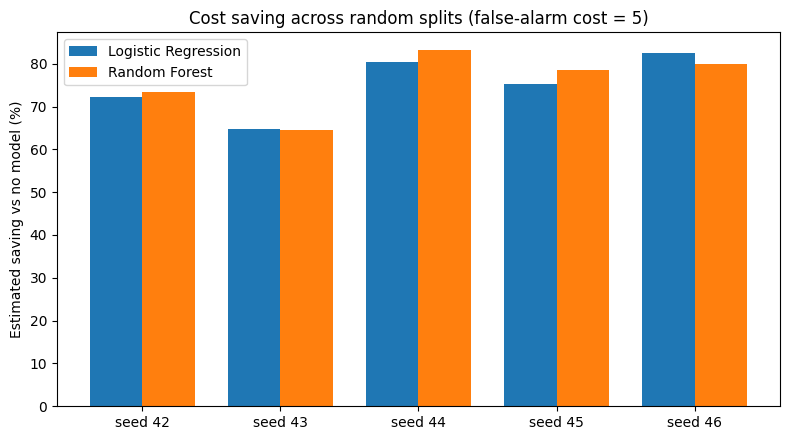

In [4]:
cols = ["PR_AUC", "Precision@0.5", "Recall@0.5", "Saving_%"]
summary = runs.groupby("Model")[cols].agg(["mean", "std", "min", "max"])
display(summary.round(3))
summary.to_csv("robustness_summary.csv")

fig, ax = plt.subplots(figsize=(8, 4.5))
width = 0.38
x = np.arange(len(SEEDS))
for i, name in enumerate(["Logistic Regression", "Random Forest"]):
    vals = runs[runs["Model"] == name]["Saving_%"].values
    ax.bar(x + (i - 0.5) * width, vals, width, label=name)
ax.set_xticks(x)
ax.set_xticklabels([f"seed {s}" for s in SEEDS])
ax.set_ylabel("Estimated saving vs no model (%)")
ax.set_title(f"Cost saving across random splits (false-alarm cost = {FALSE_ALARM_COST})")
ax.legend()
plt.tight_layout()
plt.savefig("robustness_chart.png", dpi=150)
plt.show()

## One run after removing duplicate rows

In [5]:
df_dedup = df.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(df_dedup), "| frauds:", int(df_dedup["Class"].sum()))
dedup = pd.DataFrame(run_experiment(df_dedup, 42, "duplicates removed, seed 42"))
display(dedup.round(3))
dedup.to_csv("robustness_dedup.csv", index=False)

Rows after removing duplicates: 283726 | frauds: 473


,Run,Model,Test frauds,PR_AUC,Precision@0.5,Recall@0.5,Chosen threshold,Saving_%
0,"duplicates removed, seed 42",Logistic Regression,95,0.731,0.061,0.905,0.99,78.228
1,"duplicates removed, seed 42",Random Forest,95,0.849,0.880,0.768,0.44,74.641


## How to read this

- A small spread (std) across seeds means the result does not depend on one lucky split.
- Compare the dedup run with the "seed 42" row above. If they are close, the 1,081 duplicate rows are not driving the result.
- The false-alarm cost is still an assumption, and each test set still has only about 99 frauds. This check reduces the luck-of-the-split risk but does not remove it.